In [1]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from pathlib import Path

In [2]:
base_dir = Path("/Users/angelaliu/Library/CloudStorage/OneDrive-MassachusettsInstituteofTechnology(2)/Fracture Flow UROP")
mat_path = base_dir / "Updated Code" / "compare_Np.mat"
out_pdf  = base_dir / "Updated Code" / "compareNp_1CDF.pdf"

In [3]:
N_PS    = 5
N_TRIAL = 5

bkt_1000  = [[None]*N_TRIAL for _ in range(N_PS)]
bkt_10000 = [[None]*N_TRIAL for _ in range(N_PS)]
connected = np.zeros((N_PS, N_TRIAL), dtype=bool)

with h5py.File(mat_path, 'r') as f:
    conn_raw = f['connected'][()]          # (5,5) uint8
    b1k  = f['bkt_1000']
    b10k = f['bkt_10000']

    for ps in range(N_PS):
        for tr in range(N_TRIAL):
            if conn_raw[ps, tr]:
                connected[ps, tr] = True
                bkt_1000 [ps][tr] = f[b1k [ps, tr]][()].flatten()
                bkt_10000[ps][tr] = f[b10k[ps, tr]][()].flatten()

print(f"Connected trials: {connected.sum()} / {N_PS*N_TRIAL}")
print(connected.astype(int))

Connected trials: 6 / 25
[[0 1 1 0 0]
 [0 1 1 0 0]
 [0 1 0 0 0]
 [0 0 0 0 0]
 [0 0 1 0 0]]


Saved /Users/angelaliu/Library/CloudStorage/OneDrive-MassachusettsInstituteofTechnology(2)/Fracture Flow UROP/Updated Code/compareNp_1CDF.pdf


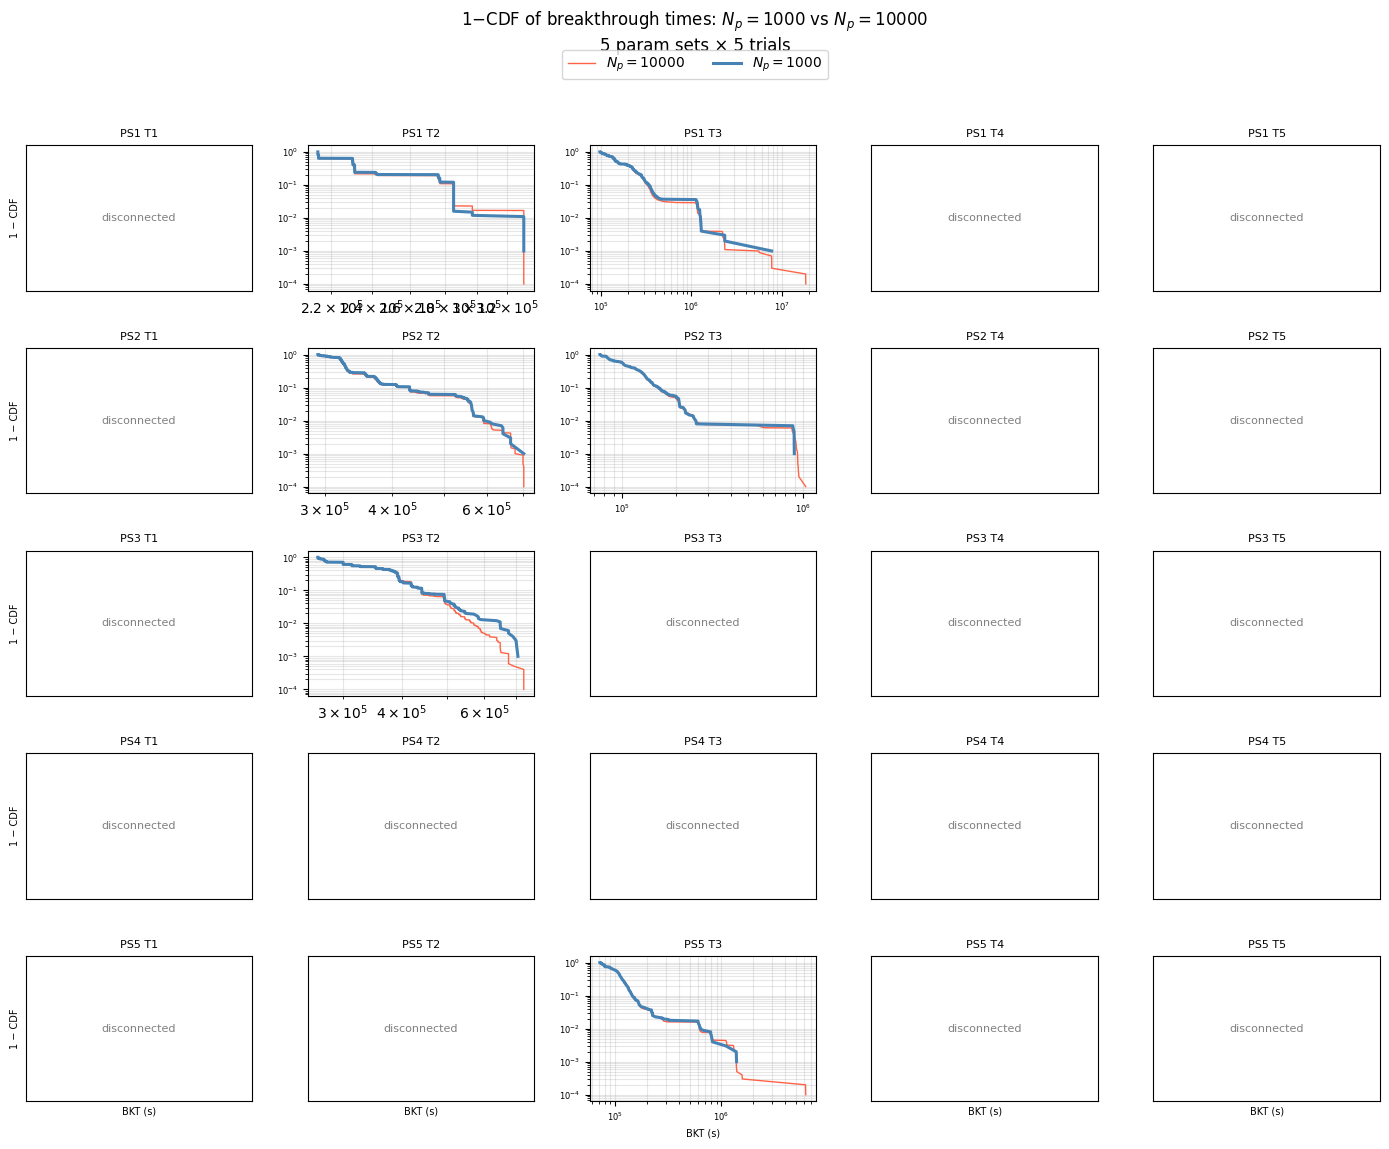

In [7]:
def survival_curve(bt):
    """Empirical 1-CDF: values 1 -> 1/n (no zeros, safe for log-log)."""
    n = len(bt)
    return bt, np.arange(n, 0, -1) / n

fig, axes = plt.subplots(N_PS, N_TRIAL, figsize=(14, 11))

for ps in range(N_PS):
    for tr in range(N_TRIAL):
        ax = axes[ps, tr]
        if connected[ps, tr]:
            t1,  s1  = survival_curve(bkt_1000 [ps][tr])
            t10, s10 = survival_curve(bkt_10000[ps][tr])
            ax.loglog(t10, s10, color='tomato',    lw=1.0, label='$N_p=10000$')
            ax.loglog(t1,  s1,  color='steelblue', lw=2.2, label='$N_p=1000$')
            ax.grid(True, which='both', alpha=0.3)
            ax.tick_params(labelsize=6)
        else:
            ax.text(0.5, 0.5, 'disconnected',
                    ha='center', va='center', transform=ax.transAxes,
                    fontsize=8, color='gray')
            ax.set_xticks([])
            ax.set_yticks([])

        ax.set_title(f'PS{ps+1} T{tr+1}', fontsize=8)

        if ps == N_PS - 1:
            ax.set_xlabel('BKT (s)', fontsize=7)
        if tr == 0:
            ax.set_ylabel('1 − CDF', fontsize=7)

# Shared legend at top
handles = [
    plt.Line2D([0], [0], color='tomato',    lw=1.0, label='$N_p = 10000$'),
    plt.Line2D([0], [0], color='steelblue', lw=2.2, label='$N_p = 1000$'),
]
fig.legend(handles=handles, loc='upper center', ncol=2,
           fontsize=10, frameon=True, bbox_to_anchor=(0.5, 1.01))

fig.suptitle('1−CDF of breakthrough times: $N_p=1000$ vs $N_p=10000$\n5 param sets × 5 trials',
             y=1.04, fontsize=12)
plt.tight_layout()

fig.savefig(out_pdf, bbox_inches='tight')
print(f'Saved {out_pdf}')
plt.show()